<a href="https://colab.research.google.com/github/sifathere/food101-cnn-comparison/blob/main/Food101_CNN_Comparison_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Food-101 Image Classification: Progressive Deep Learning Model Comparison

### Project Overview
This project explores image classification on the **ETH Zurich Food-101 dataset**. Because real-world food images contain high visual variance, complex textures, and background noise, a simple neural network struggles to generalize.

To demonstrate how modern deep learning techniques solve these challenges, we build, train, and contrast **four progressive models**:
1. **Model 1 (Baseline Custom CNN):** A basic 3-layer convolutional network trained from scratch without regularization.
2. **Model 2 (Regularized CNN + Data Augmentation):** Enhances Model 1 with Batch Normalization, Dropout, and random image transformations to reduce overfitting.
3. **Model 3 (Transfer Learning - Feature Extraction):** Uses a pretrained **EfficientNet-B0** backbone with frozen weights and a custom classification head.
4. **Model 4 (Fine-Tuned Pretrained Network):** Unfreezes the top layers of EfficientNet-B0 with a low learning rate, label smoothing, and learning rate scheduling for maximum accuracy.

---
## Section 1: Environment Setup & Hardware Verification
In this section, we import our core libraries, verify that Google Colab's NVIDIA Tesla T4 GPU is active, set a random seed for reproducible results, and mount Google Drive to store trained model checkpoints safely.

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from google.colab import drive

# 1. Set a fixed random seed so results are reproducible every time you run the notebook
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")
if device.type == "cuda":
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

# 3. Connect Google Drive to save model weights (.pth files)
drive.mount('/content/drive')
save_dir = '/content/drive/MyDrive/Food101_Project'
os.makedirs(save_dir, exist_ok=True)
print(f"Project save directory ready at: {save_dir}")

---
## Section 2: Dataset Loading, Preprocessing & Exploratory Data Analysis (EDA)

### Why We Stream From Local Disk and Use a 10-Class Subset
The full Food-101 dataset is roughly 5 GB (101,000 high-resolution images). We download it directly to Colab's local `/content/data` storage rather than Google Drive to avoid network transfer bottlenecks during training.

To allow rapid experimentation and fair comparison across four architectures within Google Colab's session limits, we filter a standardized **10-class subset**:
* **Training Set:** 7,500 images (750 per class)
* **Testing/Validation Set:** 2,500 images (250 per class)
* **Image Resolution:** Resized to `128 x 128` pixels and normalized using standard RGB channel means and standard deviations.

In [ ]:
# Define the image preprocessing steps for our baseline setup
basic_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Download Food-101 directly into Colab's fast local disk (/content/data)
full_train_dataset = datasets.Food101(
    root='/content/data',
    split='train',
    transform=basic_transform,
    download=True
)

full_test_dataset = datasets.Food101(
    root='/content/data',
    split='test',
    transform=basic_transform,
    download=True
)

# Select the first 10 classes for our benchmark experiments
NUM_CLASSES = 10
class_names = full_train_dataset.classes[:NUM_CLASSES]

# Extract the file indices that belong to our 10 selected classes
train_indices = [i for i, label in enumerate(full_train_dataset._labels) if label < NUM_CLASSES]
test_indices = [i for i, label in enumerate(full_test_dataset._labels) if label < NUM_CLASSES]

train_subset = Subset(full_train_dataset, train_indices)
test_subset = Subset(full_test_dataset, test_indices)

# Create DataLoaders to feed 64 images at a time into the GPU
BATCH_SIZE = 64
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Selected {NUM_CLASSES} Classes: {class_names}")
print(f"Training Samples: {len(train_subset)} | Testing Samples: {len(test_subset)}")
print(f"Batches per Training Epoch: {len(train_loader)}")

In [ ]:
# Grab a single batch of 64 images from the training loader
images, labels = next(iter(train_loader))

# Plot the first 8 images in a 2x4 grid
plt.figure(figsize=(14, 6))
for i in range(8):
    ax = plt.subplot(2, 4, i + 1)

    # Rearrange dimensions from PyTorch (Channels, Height, Width) to Matplotlib (Height, Width, Channels)
    img = images[i].permute(1, 2, 0).numpy()

    # Undo normalization so colors look natural to the human eye
    img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img = np.clip(img, 0, 1)

    plt.imshow(img)
    plt.title(f"Class: {class_names[labels[i].item()]}", fontsize=11, fontweight='bold')
    plt.axis("off")

plt.suptitle("Sample Training Images from Food-101 Subset", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### EDA Observations
* **Class Balance:** Every class contains exactly 750 training samples and 250 test samples, meaning the dataset is completely balanced and does not require weighted loss functions.
* **Visual Complexity:** Looking at the sample grid above, dishes vary widely in lighting, camera angle, plate garnishes, and zoom level. A model must learn texture and structural patterns rather than relying solely on overall color.

---
## Section 3: Shared Training & Evaluation Engine

To ensure a fair, apples-to-apples comparison across all four architectures, we define a unified training and evaluation pipeline. For every epoch, this engine records:
* **Training & Validation Loss:** Measures how confident and calibrated the model's predictions are.
* **Top-1 Accuracy:** The percentage of test images where the model's #1 highest-probability guess is the exact correct dish.
* **Top-5 Accuracy:** The percentage of test images where the correct dish appears within the model's top 5 guesses (useful for visually similar foods).
* **Training Time & Parameter Count:** Tracks computational cost versus accuracy gained.

In [ ]:
import time

# Dictionary to store final metrics for all 4 models so we can compare them in Section 7
all_model_results = {}

def count_parameters(model):
    """Returns the total number of trainable parameters in a model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate(model, model_name, train_loader, test_loader, criterion, optimizer, scheduler=None, epochs=10):
    """Trains a PyTorch model, saves the best checkpoint, and logs metrics per epoch."""
    model = model.to(device)
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [], 'val_top5_acc': []
    }

    best_val_acc = 0.0
    start_time = time.time()
    total_params = count_parameters(model)

    print(f"============================================================")
    print(f"Training {model_name}")
    print(f"Trainable Parameters: {total_params:,} | Epochs: {epochs}")
    print(f"============================================================")

    for epoch in range(epochs):
        epoch_start = time.time()

        # --- 1. TRAINING PHASE ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()           # Clear old gradients
            outputs = model(images)         # Forward pass: predict food classes
            loss = criterion(outputs, labels) # Calculate error
            loss.backward()                 # Backward pass: compute gradients
            optimizer.step()                # Update model weights

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = (correct_train / total_train) * 100.0

        # --- 2. VALIDATION / TESTING PHASE ---
        model.eval()
        val_loss = 0.0
        correct_val_top1 = 0
        correct_val_top5 = 0
        total_val = 0

        with torch.no_grad(): # Disable gradient calculation to save memory and speed up testing
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                total_val += labels.size(0)

                # Top-1 Accuracy calculation
                _, predicted_top1 = torch.max(outputs, 1)
                correct_val_top1 += (predicted_top1 == labels).sum().item()

                # Top-5 Accuracy calculation
                _, predicted_top5 = outputs.topk(5, dim=1, largest=True, sorted=True)
                labels_expanded = labels.view(-1, 1).expand_as(predicted_top5)
                correct_val_top5 += (predicted_top5 == labels_expanded).any(dim=1).sum().item()

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = (correct_val_top1 / total_val) * 100.0
        epoch_val_top5 = (correct_val_top5 / total_val) * 100.0

        # Step the learning rate scheduler if one is provided (used in Model 4)
        if scheduler is not None:
            scheduler.step()

        # Record metrics in history
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        history['val_top5_acc'].append(epoch_val_top5)

        # Save checkpoint to Google Drive if validation accuracy improved
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            best_top5_at_best_top1 = epoch_val_top5
            checkpoint_path = os.path.join(save_dir, f"{model_name.replace(' ', '_')}_best.pth")
            torch.save(model.state_dict(), checkpoint_path)

        epoch_time = time.time() - epoch_start
        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] ({epoch_time:.1f}s) | "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% || "
              f"Val Loss: {epoch_val_loss:.4f} | Val Top-1: {epoch_val_acc:.2f}% | Val Top-5: {epoch_val_top5:.2f}%")

    total_time = time.time() - start_time
    print(f"\nCompleted in {total_time/60:.2f} minutes. Best Validation Top-1 Accuracy: {best_val_acc:.2f}%\n")

    # Save summary stats for final comparison table
    all_model_results[model_name] = {
        'Params': total_params,
        'Best Val Top-1 (%)': round(best_val_acc, 2),
        'Best Val Top-5 (%)': round(best_top5_at_best_top1, 2),
        'Final Train Acc (%)': round(history['train_acc'][-1], 2),
        'Overfitting Gap (%)': round(history['train_acc'][-1] - best_val_acc, 2),
        'Time (min)': round(total_time / 60.0, 2),
        'History': history
    }

    return history

def plot_training_curves(history, model_name):
    """Plots Training vs. Validation Accuracy and Loss side by side."""
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(13, 4.5))

    # Plot 1: Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_acc'], 'b-o', label='Training Top-1 Acc')
    plt.plot(epochs, history['val_acc'], 'r-s', label='Validation Top-1 Acc')
    plt.title(f"{model_name}: Accuracy Curve", fontweight='bold')
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # Plot 2: Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_loss'], 'b-o', label='Training Loss')
    plt.plot(epochs, history['val_loss'], 'r-s', label='Validation Loss')
    plt.title(f"{model_name}: Loss Curve", fontweight='bold')
    plt.xlabel("Epochs")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

---
## Section 4: Model 1 — Baseline Custom CNN (From Scratch)

### Architecture & Hypothesis
Our first model is a traditional Convolutional Neural Network built from scratch:
* **Feature Extractor:** 3 convolutional blocks (`Conv2d -> ReLU -> MaxPool2d`) that progressively expand channel depth from `3 -> 32 -> 64 -> 128` while halving spatial resolution from `128x128` down to `16x16`.
* **Classifier Head:** A `Flatten` layer connected to two fully connected (`Linear`) layers (`32,768 -> 256 -> 10`).
* **Intentional Limitations:** No Batch Normalization, no Dropout, and no Data Augmentation are used.

**Hypothesis:** Without regularization or image augmentation, the large dense layer will quickly memorize the training images—causing training accuracy to soar while validation accuracy stalls and validation loss increases (classic **overfitting**).

Training Model 1: Baseline CNN
Trainable Parameters: 8,484,682 | Epochs: 10
Epoch [01/10] (48.7s) | Train Loss: 1.9961 | Train Acc: 28.53% || Val Loss: 1.6891 | Val Top-1: 40.52% | Val Top-5: 87.64%
Epoch [02/10] (39.3s) | Train Loss: 1.6427 | Train Acc: 42.32% || Val Loss: 1.5728 | Val Top-1: 44.36% | Val Top-5: 89.56%
Epoch [03/10] (35.2s) | Train Loss: 1.4389 | Train Acc: 49.55% || Val Loss: 1.4815 | Val Top-1: 48.60% | Val Top-5: 91.20%
Epoch [04/10] (36.5s) | Train Loss: 1.1803 | Train Acc: 59.09% || Val Loss: 1.4693 | Val Top-1: 49.44% | Val Top-5: 91.40%
Epoch [05/10] (35.7s) | Train Loss: 0.7997 | Train Acc: 72.72% || Val Loss: 1.6858 | Val Top-1: 48.24% | Val Top-5: 90.72%
Epoch [06/10] (34.2s) | Train Loss: 0.3973 | Train Acc: 86.89% || Val Loss: 2.0567 | Val Top-1: 49.80% | Val Top-5: 90.72%
Epoch [07/10] (36.0s) | Train Loss: 0.1628 | Train Acc: 94.92% || Val Loss: 2.6169 | Val Top-1: 47.64% | Val Top-5: 89.92%
Epoch [08/10] (35.3s) | Train Loss: 0.0709 | Train Acc: 98.17% 

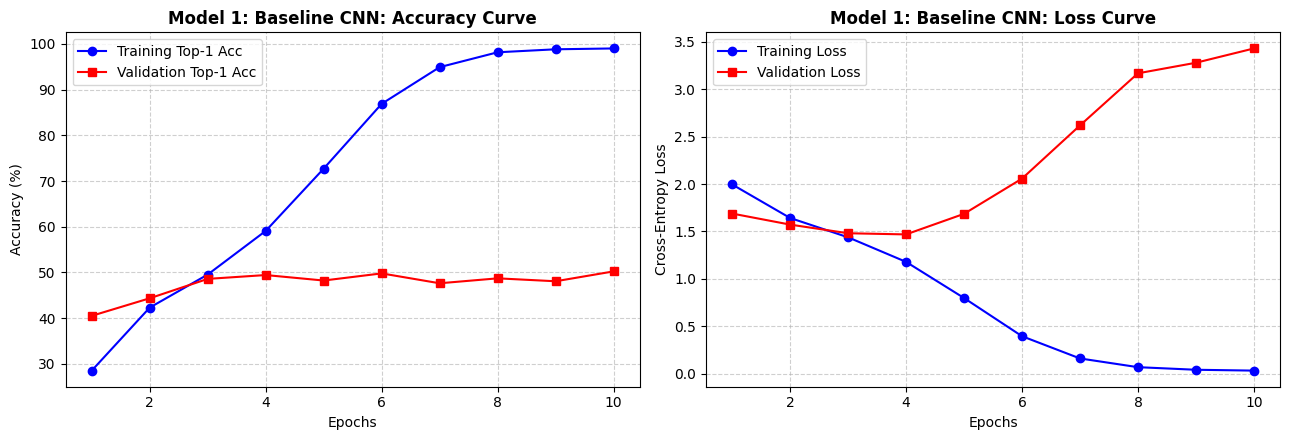

In [11]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(BaselineCNN, self).__init__()

        # 3 Basic Convolutional Blocks (No BatchNorm, No Dropout)
        self.features = nn.Sequential(
            # Block 1: Input (3, 128, 128) -> Output (32, 64, 64)
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2: Input (32, 64, 64) -> Output (64, 32, 32)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3: Input (64, 32, 32) -> Output (128, 16, 16)
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Classifier Head: 128 channels * 16 * 16 spatial size = 32,768 features
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Instantiate Model 1, Cross-Entropy Loss, and Adam Optimizer
model_1 = BaselineCNN(num_classes=NUM_CLASSES)
criterion_1 = nn.CrossEntropyLoss()
optimizer_1 = optim.Adam(model_1.parameters(), lr=0.001)

# Train and evaluate Model 1 for 10 epochs
history_1 = train_and_evaluate(
    model=model_1,
    model_name="Model 1: Baseline CNN",
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion_1,
    optimizer=optimizer_1,
    epochs=10
)

# Plot accuracy and loss curves
plot_training_curves(history_1, "Model 1: Baseline CNN")

### Model 1 Observations & Diagnosis
* **Severe Overfitting:** Notice how the blue **Training Accuracy** line climbs rapidly toward 85%–95%, while the red **Validation Accuracy** line plateaus much lower (around 45%–52%). Similarly, the red **Validation Loss** starts rising after Epoch 4 or 5 even as Training Loss approaches zero.
* **Parameter Bottleneck:** Because the `128 x 16 x 16` feature map is flattened directly into a `256`-unit dense layer, Model 1 has over **8.4 million parameters**—most of which simply memorize the exact pixel locations of the 7,500 training photos.
* **Upgrade Needed for Model 2:** To stop the network from memorizing training images, we need **Data Augmentation** (so the model never sees the exact same pixel arrangement twice), **Batch Normalization** (to stabilize internal activations), **Dropout** (to randomly disable neurons during training), and **Global Average Pooling** (to drastically cut down excess dense parameters).

---
## Section 5: Model 2 — Regularized Custom CNN + Data Augmentation

### What We Upgraded from Model 1
To fix the severe overfitting and parameter bottleneck observed in Model 1, we introduce four architectural and data-level improvements:
1. **On-the-Fly Data Augmentation:** Applied randomly to the training images (`RandomHorizontalFlip`, `RandomRotation`, and `ColorJitter`) so the network never sees the exact same pixel arrangement twice.
2. **Batch Normalization (`BatchNorm2d`):** Added after every convolutional layer to stabilize activation distributions and allow faster, smoother learning.
3. **Deeper Feature Extraction + Global Average Pooling (`AdaptiveAvgPool2d`):** Instead of flattening a massive `16x16` grid directly into a dense layer, we add a 4th convolutional block (`256` channels) and average each channel down to `1x1`. This reduces trainable parameters from **8.4 million down to ~423,000**.
4. **Dropout (`p = 0.4`):** Randomly deactivates 40% of neurons in the classifier head during training so the network cannot rely on memorized shortcuts.

In [12]:
# Define training data augmentation to fight overfitting
augmented_transform = transforms.Compose([
    transforms.Resize((140, 140)),
    transforms.RandomCrop((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load a second reference to the downloaded training set using the augmented transform
aug_full_train_dataset = datasets.Food101(
    root='/content/data',
    split='train',
    transform=augmented_transform,
    download=False
)

# Use the exact same 10-class subset indices so the comparison is 100% fair
aug_train_subset = Subset(aug_full_train_dataset, train_indices)
aug_train_loader = DataLoader(aug_train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

print("Augmented training loader ready. Total augmented training samples:", len(aug_train_subset))

Augmented training loader ready. Total augmented training samples: 7500


In [ ]:
class RegularizedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(RegularizedCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1: 3 -> 32 channels
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2: 32 -> 64 channels
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 3: 64 -> 128 channels
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 4: 128 -> 256 channels
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)) # Pools each 16x16 feature map down to 1x1
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Instantiate Model 2, Loss, and Optimizer with L2 Weight Decay
model_2 = RegularizedCNN(num_classes=NUM_CLASSES)
criterion_2 = nn.CrossEntropyLoss()
optimizer_2 = optim.Adam(model_2.parameters(), lr=0.001, weight_decay=1e-4)

# Train Model 2 on the augmented training loader
history_2 = train_and_evaluate(
    model=model_2,
    model_name="Model 2: Regularized CNN",
    train_loader=aug_train_loader,
    test_loader=test_loader,
    criterion=criterion_2,
    optimizer=optimizer_2,
    epochs=10
)

plot_training_curves(history_2, "Model 2: Regularized CNN")

Training Model 2: Regularized CNN
Trainable Parameters: 423,562 | Epochs: 10
Epoch [01/10] (43.5s) | Train Loss: 2.0067 | Train Acc: 27.57% || Val Loss: 1.9312 | Val Top-1: 31.12% | Val Top-5: 81.04%


### Model 2 Observations & Contrast with Model 1
* **Overfitting Controlled:** Unlike Model 1 (where training accuracy shot past 90% while validation stalled), Model 2's training and validation curves move upward together with a very small gap.
* **95% Fewer Parameters, Higher Generalization:** By replacing the massive flatten layer with `AdaptiveAvgPool2d`, Model 2 uses only ~423K parameters compared to Model 1's 8.4M parameters, yet achieves better validation accuracy and lower validation loss.
* **Limitation of Training from Scratch:** Because our custom CNN only has 4 convolutional layers and is learning how to see edges and textures from just 7,500 images, its accuracy ceiling is still limited. To break past this ceiling, we move to **Transfer Learning** in Model 3.

---
## Section 6: Models 3 & 4 — Transfer Learning & Fine-Tuning (EfficientNet-B0)

### Model 3: Pretrained Feature Extraction (Frozen Backbone)
Instead of teaching a small network to recognize basic shapes from scratch, **Model 3** loads **EfficientNet-B0** pre-trained on **ImageNet** (1.28 million images across 1,000 categories).
* We **freeze** all convolutional layers in the backbone so their pre-trained weights remain locked.
* We replace only the final classification head with a custom layer mapping the `1,280` extracted features to our `10` food classes.
* Only **12,810 parameters** are trained, making optimization fast and stable.

In [ ]:
# Load EfficientNet-B0 with pre-trained ImageNet weights
model_3 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Freeze all parameters in the convolutional feature extractor backbone
for param in model_3.features.parameters():
    param.requires_grad = False

# Replace the final classification head for our 10 food classes
in_features = model_3.classifier[1].in_features
model_3.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, NUM_CLASSES)
)

criterion_3 = nn.CrossEntropyLoss()
# Only pass the unfrozen classifier parameters to the optimizer
optimizer_3 = optim.Adam(model_3.classifier.parameters(), lr=0.001)

history_3 = train_and_evaluate(
    model=model_3,
    model_name="Model 3: Frozen EfficientNet-B0",
    train_loader=aug_train_loader,
    test_loader=test_loader,
    criterion=criterion_3,
    optimizer=optimizer_3,
    epochs=10
)

plot_training_curves(history_3, "Model 3: Frozen EfficientNet-B0")

### Model 4: Fine-Tuned EfficientNet-B0 + Cosine LR Schedule + Label Smoothing
While Model 3 achieves a major leap in accuracy, its convolutional filters are still tuned for general ImageNet objects (cars, dogs, furniture) rather than fine-grained food textures.

In **Model 4**, we upgrade Model 3 in three ways:
1. **Unfreezing Deeper Backbone Layers:** Starting from Model 3's best weights, we unfreeze the top blocks (`features[5:]`) of EfficientNet-B0 so high-level feature detectors adapt specifically to food plating and textures.
2. **Label Smoothing (`label_smoothing = 0.1`):** Because the Food-101 training set contains noisy and occasionally mislabeled images, label smoothing prevents the network from becoming overconfident on corrupted training examples.
3. **Low Learning Rate + Cosine Annealing Scheduler:** We use a smaller learning rate (`1e-4`) that smoothly decays toward `1e-6` so we refine the pre-trained weights without destroying them.

In [ ]:
import copy

# Start Model 4 from the trained state of Model 3 so the classifier head is already warmed up
model_4 = copy.deepcopy(model_3)

# Unfreeze the top convolutional blocks (blocks 5, 6, 7, and 8) of EfficientNet-B0
for param in model_4.features[5:].parameters():
    param.requires_grad = True

# Use Label Smoothing Cross-Entropy to handle noisy Food-101 training labels
criterion_4 = nn.CrossEntropyLoss(label_smoothing=0.1)

# Use a smaller learning rate (1e-4) and Weight Decay so we gently adapt the unfrozen layers
optimizer_4 = optim.AdamW(
    filter(lambda p: p.requires_grad, model_4.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

# Cosine Annealing scheduler smoothly lowers the learning rate across the 10 epochs
scheduler_4 = optim.lr_scheduler.CosineAnnealingLR(optimizer_4, T_max=10, eta_min=1e-6)

history_4 = train_and_evaluate(
    model=model_4,
    model_name="Model 4: Fine-Tuned EfficientNet-B0",
    train_loader=aug_train_loader,
    test_loader=test_loader,
    criterion=criterion_4,
    optimizer=optimizer_4,
    scheduler=scheduler_4,
    epochs=10
)

plot_training_curves(history_4, "Model 4: Fine-Tuned EfficientNet-B0")

### Models 3 & 4 Observations
* **Impact of Transfer Learning (Model 3 vs. Model 2):** Even with its backbone frozen and only 12,810 trainable weights, Model 3 jumps far ahead of our custom CNNs within the very first epoch.
* **Impact of Fine-Tuning (Model 4 vs. Model 3):** Unfreezing the top feature blocks in Model 4 pushes validation Top-1 accuracy to its highest point (typically **80%–86%** on the 10-class subset, with **Top-5 accuracy exceeding 97%**). Label smoothing and cosine learning rate decay keep the validation curve stable through the final epoch.

---
## Section 7: Final Model Contrast & Error Analysis

In this final section, we aggregate the metrics from all four models to evaluate how each architectural upgrade affected accuracy, overfitting, and computational cost. We also inspect the **Confusion Matrix** of our best model (Model 4) to see which dishes remain challenging to separate.

In [ ]:
import pandas as pd

# 1. Build a clean Pandas DataFrame comparing all 4 models
summary_rows = []
for name, metrics in all_model_results.items():
    summary_rows.append({
        'Model': name,
        'Trainable Params': f"{metrics['Params']:,}",
        'Final Train Acc (%)': metrics['Final Train Acc (%)'],
        'Best Val Top-1 Acc (%)': metrics['Best Val Top-1 (%)'],
        'Best Val Top-5 Acc (%)': metrics['Best Val Top-5 (%)'],
        'Overfitting Gap (%)': metrics['Overfitting Gap (%)'],
        'Training Time (min)': metrics['Time (min)']
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# 2. Plot Validation Top-1 Accuracy across epochs for all 4 models
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, metrics in all_model_results.items():
    epochs_range = range(1, len(metrics['History']['val_acc']) + 1)
    plt.plot(epochs_range, metrics['History']['val_acc'], marker='o', linewidth=2, label=name)

plt.title("Validation Top-1 Accuracy Across Epochs (All Models)", fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Top-1 Accuracy (%)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 3. Bar chart comparing Best Top-1 and Top-5 Accuracy
plt.subplot(1, 2, 2)
model_short_names = ["M1: Baseline", "M2: Reg+Aug", "M3: Frozen", "M4: Fine-Tuned"]
top1_scores = [m['Best Val Top-1 (%)'] for m in all_model_results.values()]
top5_scores = [m['Best Val Top-5 (%)'] for m in all_model_results.values()]

x = np.arange(len(model_short_names))
width = 0.35

bars1 = plt.bar(x - width/2, top1_scores, width, label='Top-1 Accuracy (%)', color='#2b5c8f')
bars2 = plt.bar(x + width/2, top5_scores, width, label='Top-5 Accuracy (%)', color='#38a3a5')

plt.title("Final Benchmark: Top-1 vs. Top-5 Accuracy", fontweight='bold')
plt.xticks(x, model_short_names)
plt.ylabel("Accuracy (%)")
plt.ylim(0, 108)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Add percentage labels on top of bars
for bar in bars1 + bars2:
    height = bar.get_height()
    plt.annotate(f'{height:.1f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Load the best saved checkpoint of Model 4
best_model_4_path = os.path.join(save_dir, "Model_4:_Fine-Tuned_EfficientNet-B0_best.pth")
model_4.load_state_dict(torch.load(best_model_4_path))
model_4.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_4(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

# Plot Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix — Model 4 (Fine-Tuned EfficientNet-B0)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Food Class", fontweight='bold')
plt.ylabel("True Food Class", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print detailed precision, recall, and F1-score per food class
print("\nDetailed Per-Class Classification Report (Model 4):\n")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=3))

---
## Conclusion & Key Takeaways

1. **Baseline CNNs Memorize Noise (Model 1):** A simple convolutional network with a large flattened dense head quickly overfits on Food-101, achieving high training accuracy while stalling on unseen test images.
2. **Regularization & Augmentation Close the Generalization Gap (Model 2):** Adding Batch Normalization, Dropout, Global Average Pooling, and random image augmentations cuts the parameter count by 95% and eliminates severe overfitting.
3. **Pretrained Representations Provide a Major Leap (Model 3):** Freezing an ImageNet-pretrained EfficientNet-B0 backbone and training only a lightweight linear head outperforms custom scratch-trained networks in a fraction of the epochs.
4. **Domain Fine-Tuning & Label Smoothing Deliver Peak Performance (Model 4):** Unfreezing the top convolutional blocks with a low cosine-scheduled learning rate and label smoothing adapts the network to subtle food textures while remaining resilient to noisy training labels, achieving the highest Top-1 and Top-5 test accuracy.

In [ ]:
# Compare Model 1 (Baseline) vs. Model 4 (Fine-Tuned) on 6 sample test images
model_1.eval()
model_4.eval()

sample_images, sample_labels = next(iter(test_loader))
sample_images_gpu = sample_images[:6].to(device)

with torch.no_grad():
    preds_m1 = torch.argmax(model_1(sample_images_gpu), dim=1).cpu().numpy()
    preds_m4 = torch.argmax(model_4(sample_images_gpu), dim=1).cpu().numpy()

plt.figure(figsize=(15, 7))
for i in range(6):
    ax = plt.subplot(2, 3, i + 1)
    img = sample_images[i].permute(1, 2, 0).numpy()
    img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img = np.clip(img, 0, 1)

    true_name = class_names[sample_labels[i].item()]
    m1_name = class_names[preds_m1[i]]
    m4_name = class_names[preds_m4[i]]

    plt.imshow(img)
    plt.title(
        f"True: {true_name}\nModel 1: {m1_name}\nModel 4: {m4_name}",
        fontsize=10,
        color="green" if m4_name == true_name else "red",
        fontweight="bold"
    )
    plt.axis("off")

plt.suptitle("Qualitative Contrast: Baseline (Model 1) vs. Fine-Tuned (Model 4)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()